In [13]:
import numpy as np
import pandas as pd
import os
from matplotlib import pyplot as plt
import json
import csv
import os
import scipy as sp
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.metrics.pairwise import cosine_similarity
from geomstats.geometry.spd_matrices import SPDMatrices
from pyriemann.utils.distance import distance_riemann
from pyriemann.utils.distance import pairwise_distance

In [14]:
# data_path
one_clst_path = "./set1_one_cluster.jsonl"
two_clst_path = r"./set1_two_cluster.jsonl"
three_clst_path = r"./set1_three_cluster.jsonl"

In [15]:
def load_data_from_jsonl(jsonl_path):

    data = pd.read_json(jsonl_path, lines=True, encoding='utf-8')

    gamma_list = data["gamma_list"][0]
    theta_list = data["theta_list"][0]
    labels = data["labels"]

    return np.array(gamma_list), np.array(theta_list), np.array(labels)

In [16]:
gamma_list_clst_1, theta_list_clst_1, labels_clst_1 = load_data_from_jsonl(one_clst_path)
gamma_list_clst_2, theta_list_clst_2, labels_clst_2 = load_data_from_jsonl(two_clst_path)
gamma_list_clst_3, theta_list_clst_3, labels_clst_3 = load_data_from_jsonl(three_clst_path)

## solving with solver

In [17]:
# !pip install cvxpy

In [18]:
import cvxpy as cp
print(cp.installed_solvers())

['CLARABEL', 'HIGHS', 'OSQP', 'SCIPY', 'SCS']


In [19]:
# osqp

def solver_cvxpy_cvxopt(gamma_list, theta_list, zeta):
    N = len(gamma_list)
    p = theta_list[0].shape[0]

    # set the optimize variable
    x = [cp.Variable(p) for _ in range(N)]
    z = [cp.Variable(p) for _ in range(N)]

    #objective
    quad_term = []

    for i in range(N):
        diff = x[i] - theta_list[i]
        quad_term.append(cp.quad_form(diff, gamma_list[i])) # (x-theta) @ Gamma @ (x-theta)

    z_sum = sum(z)
    l1_term = zeta * cp.norm1(z_sum) #l1 term

    obj = cp.Minimize(cp.sum(quad_term) + l1_term)

    #set constraints x_i = z_i
    constrains = [x[i] == z[i] for i in range(N)]

    prob = cp.Problem(obj, constrains) #define problems
    prob.solve(solver=cp.CVXOPT) #using solver osqp to solve problem - OSQP using ADMM

    x_val = [xi.value for xi in x]
    z_val = [zi.value for zi in z]

    return prob.value, x_val, z_val

In [20]:
obj_cvxpy_osqp, x_cvsxpy_osqp, z_cvxpy_osqp, cvxpy_osqp_solver_stats  = solver_cvxpy_cvxopt(gamma_list, theta_list, zeta=1.0)

print("CVXPy objective with OSQP solver:", obj_cvxpy_osqp)

print("Gap between own ADMM vs OSQP sovlver:", obj_admm_ - obj_cvxpy_osqp)

NameError: name 'gamma_list' is not defined

In [21]:
print("Number of the iteration:", cvxpy_osqp_solver_stats.num_iters)
print("Primal res:", cvxpy_osqp_solver_stats.extra_stats.info)

NameError: name 'cvxpy_osqp_solver_stats' is not defined

## Cluster


In [72]:
# 1 cluster
# clst_admm = r"../results/cluster/c1_vanilla_admm_results_summary.jsonl"
# mtgp_optim = r"../results/cluster/mtgp_sweep_alpha/set1_one_cluster/jsonl/iota_0.9_alpha_0.9600_Q_5_rank_1_train_300_lr_0.03.jsonl"
# sogp_optim = r"../results/cluster/sogp_sweep_alpha/set1_one_cluster/jsonl/iota_0.6_alpha_0.8500_train_100_lr_0.01.jsonl"

# 1 cluster each have mtgp
# clst_admm = r"../results/cluster/c1_vanilla_admm_results_summary.jsonl"
# mtgp_optim = r"../results/cluster_specific_mtgp/clustered_specific_1.0_0.96_set1_one_cluster.jsonl"
# sogp_optim = r"../results/cluster/sogp_sweep_alpha/set1_one_cluster/jsonl/iota_0.6_alpha_0.8500_train_100_lr_0.01.jsonl"

# 2 clst
# clst_admm = r"../results/cluster/c2_vanilla_admm_results_summary.jsonl"
# mtgp_optim = r"../results/cluster/mtgp_sweep_alpha/set1_two_cluster/jsonl/iota_1.2_alpha_0.9600_Q_5_rank_1_train_300_lr_0.03.jsonl"
# sogp_optim = r"../results/cluster/sogp_sweep_alpha/set1_two_cluster/jsonl/iota_1.1_alpha_0.8500_train_100_lr_0.01.jsonl"

# clst_admm = r"../results/cluster/c2_vanilla_admm_results_summary.jsonl"
# mtgp_optim = r"../results/cluster_specific_mtgp/clustered_specific_1.2_0.96_set1_two_cluster.jsonl"
# sogp_optim = r"../results/cluster/sogp_sweep_alpha/set1_two_cluster/jsonl/iota_1.1_alpha_0.8500_train_100_lr_0.01.jsonl"

# 3 clst
# clst_admm = r"../results/cluster/c3_vanilla_admm_results_summary.jsonl"
# mtgp_optim = r"../results/cluster/mtgp_sweep_alpha/set1_three_cluster/jsonl/iota_1_alpha_0.9600_Q_5_rank_1_train_300_lr_0.03.jsonl"
# sogp_optim = r"../results/cluster/sogp_sweep_alpha/set1_three_cluster/jsonl/iota_0.5_alpha_0.8000_train_100_lr_0.01.jsonl"

clst_admm = r"../results/cluster/c3_vanilla_admm_results_summary.jsonl"
mtgp_optim = r"../results/cluster_specific_mtgp/clustered_specific_1.0_0.96_set1_three_cluster.jsonl"
sogp_optim = r"../results/cluster/sogp_sweep_alpha/set1_three_cluster/jsonl/iota_0.5_alpha_0.8000_train_100_lr_0.01.jsonl"

In [73]:
# vanilla
vanilla_data = pd.read_json(clst_admm, lines=True)
sogp_data = pd.read_json(sogp_optim, lines=True)
mtgp_data = pd.read_json(mtgp_optim, lines=True)

In [74]:
# SOGP
primal_residual_sogp = sogp_data["primal_residual"]
dual_residual_sogp = sogp_data["dual_residual"]
obj_val_sogp = sogp_data["obj_val"]

# MTGP
primal_residual_mtgp = mtgp_data["primal_residual"]
dual_residual_mtgp = mtgp_data["dual_residual"]
obj_val_mtgp = mtgp_data["obj_val"]

# vanilla

primal_residual_vanilla = vanilla_data["primal_residual"]
dual_residual_vanilla = vanilla_data["dual_residual"]
obj_val_vanilla = vanilla_data["obj_val"]

In [75]:
# obj - using the objective of the vanilla admm

exact_obj = np.array(obj_val_vanilla)[-1]
exact_obj

np.float64(4.101944974352843)

## Relative Obj Error - Dual Res - Primal res

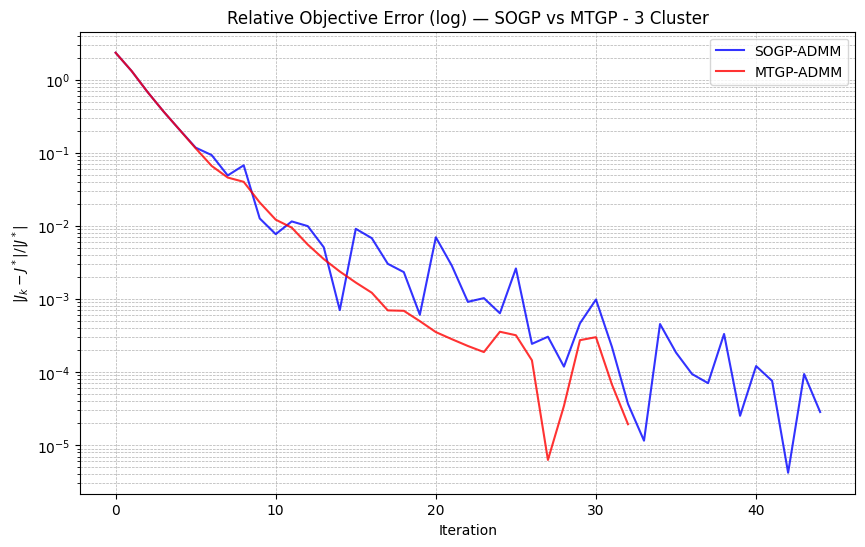

In [76]:
x_axis_sogp = np.arange(len(obj_val_sogp))
x_axis_mtgp = np.arange(len(obj_val_mtgp))
x_axis_vanilla = np.arange(len(obj_val_vanilla))

sogp_rel_err = np.abs(obj_val_sogp - exact_obj) / max(np.abs(exact_obj), 1e-12)
mtgp_rel_err = np.abs(obj_val_mtgp - exact_obj) / max(np.abs(exact_obj), 1e-12)
# vanilla_rel_err = np.abs(obj_val_vanilla - exact_obj) / max(np.abs(exact_obj), 1e-12)

plt.figure(figsize=(10,6))
plt.plot(x_axis_sogp, np.maximum(sogp_rel_err, 1e-14), color="blue", alpha=0.8, label="SOGP-ADMM")
plt.plot(x_axis_mtgp, np.maximum(mtgp_rel_err, 1e-14), color="red", alpha=0.8, label="MTGP-ADMM")
# plt.plot(x_axis_vanilla, np.maximum(vanilla_rel_err, 1e-14), color="orange", alpha=0.8, label="Exact ADMM")
plt.yscale("log")
plt.title("Relative Objective Error (log) — SOGP vs MTGP - 3 Cluster")
plt.xlabel("Iteration")
plt.ylabel(r"$|J_k - J^*|/|J^*|$")
plt.legend()
plt.grid(True, which="both", linestyle="--", linewidth=0.5)
plt.show()

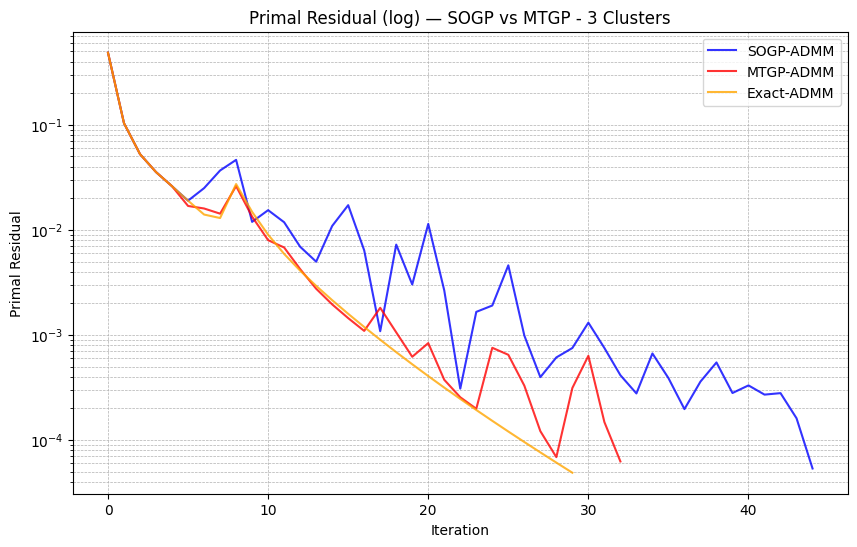

In [77]:
# primal residual
plt.figure(figsize=(10,6))
plt.plot(x_axis_sogp, np.maximum(primal_residual_sogp, 1e-12), color="blue", alpha=0.8, label="SOGP-ADMM")
plt.plot(x_axis_mtgp, np.maximum(primal_residual_mtgp, 1e-12), color="red", alpha=0.8, label="MTGP-ADMM")
plt.plot(x_axis_vanilla, np.maximum(primal_residual_vanilla, 1e-12), color="orange", alpha=0.8, label="Exact-ADMM")
plt.yscale("log")
plt.title("Primal Residual (log) — SOGP vs MTGP - 3 Clusters")
plt.xlabel("Iteration")
plt.ylabel("Primal Residual")
plt.legend()
plt.grid(True, which="both", linestyle="--", linewidth=0.5)
plt.show()

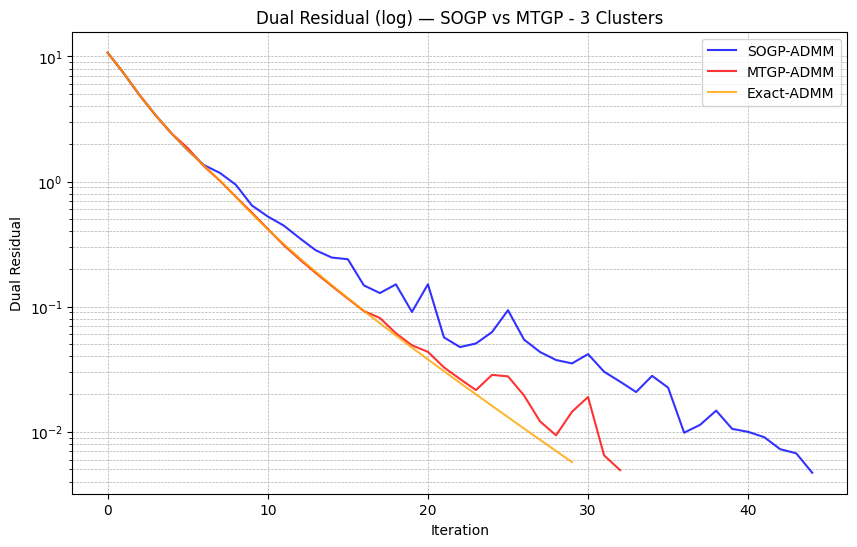

In [78]:
# dual residual
plt.figure(figsize=(10,6))
plt.plot(x_axis_sogp, np.maximum(dual_residual_sogp, 1e-12), color="blue", alpha=0.8, label="SOGP-ADMM")
plt.plot(x_axis_mtgp, np.maximum(dual_residual_mtgp, 1e-12), color="red", alpha=0.8, label="MTGP-ADMM")
plt.plot(x_axis_vanilla, np.maximum(dual_residual_vanilla, 1e-12), color="orange", alpha=0.8, label="Exact-ADMM")
plt.yscale("log")
plt.title("Dual Residual (log) — SOGP vs MTGP - 3 Clusters")
plt.xlabel("Iteration")
plt.ylabel("Dual Residual")
plt.legend()
plt.grid(True, which="both", linestyle="--", linewidth=0.5)
plt.show()

## 2. Variance and query

In [79]:
def extract_row_stats(other_stats_row, query_key="do_query"):

    # handleing the fist iteration do not use the GP -> not having stats value
    
    if not isinstance(other_stats_row, list) or len(other_stats_row) == 0:
        return np.nan, np.nan, np.nan, np.nan, 0, 0

    # activte after burn in
    active = [d for d in other_stats_row if isinstance(d, dict) and len(d) > 0]
    if len(active) == 0:
        return np.nan, np.nan, np.nan, np.nan, 0, 0

    # colects each agents var_max 
    var_list = [float(d.get("var_max", np.nan)) for d in active]

    # colect each agent psik
    psi_list = [float(d.get("psi_k", np.nan)) for d in active]

    # colect each agetn query decision
    q_list = [bool(d.get(query_key, False)) for d in active]

    return (
        np.nanmax(var_list),  # get var_max_max at this iteration
        np.nanmean(var_list),  # var_max_mean
        np.nanmean(psi_list),  # psi_k_mean
        np.nanmin(psi_list),  # psi_k_min
        int(np.sum(q_list)),
        q_list
    )

In [80]:
tmp = sogp_data["other_stats"].apply(lambda row: extract_row_stats(row, "do_query"))
sogp_data["var_max_max"] = tmp.apply(lambda x: x[0])
sogp_data["var_max_mean"] = tmp.apply(lambda x: x[1])
sogp_data["psi_k_mean"] = tmp.apply(lambda x: x[2])
sogp_data["psi_k_min"] = tmp.apply(lambda x: x[3])
sogp_data["query_count"] = tmp.apply(lambda x: x[4])
sogp_stats_query_data = tmp.apply(lambda x: x[5])

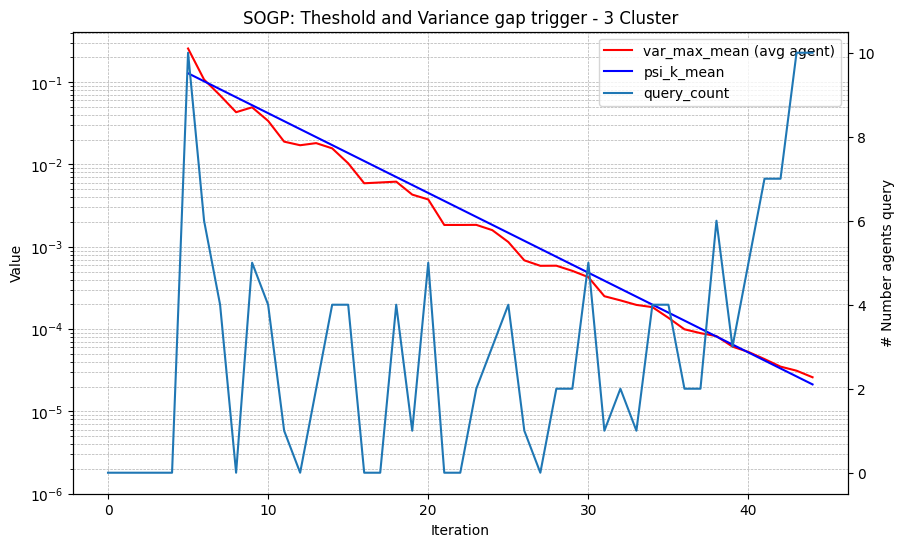

In [81]:
it = sogp_data["iteration"].to_numpy()

fig, ax = plt.subplots(figsize=(10,6))
# ax.plot(it, sogp_data["var_max_max"], color = "red",  label="var_max_max (worst agent)")
ax.plot(it, sogp_data["var_max_mean"], color = "red", label="var_max_mean (avg agent)")
ax.plot(it, sogp_data["psi_k_mean"], color = "blue",label="psi_k_mean")
ax.set_xlabel("Iteration")
ax.set_ylabel("Value")
ax.set_yscale("log")
ax.set_ylim(1e-6, None)
ax.grid(True, which="both", linestyle="--", linewidth=0.5)

ax2 = ax.twinx()
ax2.plot(it, sogp_data["query_count"], label="query_count")
ax2.set_ylabel("# Number agents query")
ax2.set_ylim(-0.5, 10.5)

lines = ax.get_lines() + ax2.get_lines()
labels = [l.get_label() for l in lines]
ax.legend(lines, labels, loc="upper right")

plt.title("SOGP: Theshold and Variance gap trigger - 3 Cluster")
plt.show()


In [82]:
# extract the query per iteration
def extract_query_stats(query_data):
    query_table = []
    for i in range(len(query_data)):
        if query_data[i] == 0:
            pass
        else:
            iter_query = query_data[i]
            query_table.append(iter_query)

    return query_table

query_table = extract_query_stats(sogp_stats_query_data)
# summ through the axis-0
# query_table
query_distr = np.sum(query_table, axis=0)

agent = np.linspace(1, 10, num=10)
agent

array([ 1.,  2.,  3.,  4.,  5.,  6.,  7.,  8.,  9., 10.])

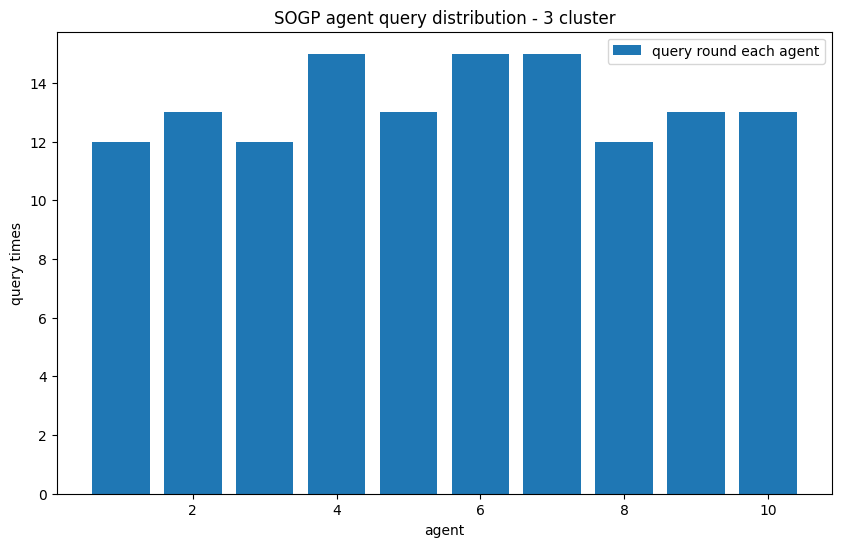

In [83]:
plt.figure(figsize=(10,6))
plt.bar(agent, query_distr, label="query round each agent")
plt.title("SOGP agent query distribution - 3 cluster")
plt.xlabel("agent")
plt.ylabel("query times")
plt.legend()
# plt.grid(True)
plt.show()

In [84]:
# gradint prdiction comparison
def plot_grads_error_per_iter(grad_per_iter_data, method):
    prediction_error = grad_per_iter_data["grads_error_per_iter"]
    # len(prediction_error)
    # getting the norm 1 error
    error_per_iter = []
    num_query_iter = 0

    for i in range(len(prediction_error)):
    # print(prediction_error[i])
        if (np.array(prediction_error[i]) == 0).all():
            pass
        else: 
            num_query_iter += 1
            l1_error = np.sum(prediction_error[i])
            error_per_iter.append(l1_error)

    if method == "sogp":    
        # plot the gradient
        plt.figure(figsize=(10,6))
        plt.plot(np.linspace(0, num_query_iter-1, num=num_query_iter), error_per_iter, color="blue", alpha=0.8, label="l1 norm gradient each iter")
        plt.yscale('log')
        plt.title("Gradient trajectory of non-comm iteration - GP-ADMM")
        plt.xlabel("iteration")
        plt.ylabel("l1 norm grad")
        plt.legend()
        plt.grid(True, which="both", linestyle="--", linewidth=0.5)
        plt.show()
        return error_per_iter, num_query_iter

    else:
        plt.figure(figsize=(10,6))
        plt.plot(np.linspace(0, num_query_iter-1, num=num_query_iter), error_per_iter, color="blue", alpha=0.8, label="l1 norm gradient each iter")
        plt.yscale('log')
        plt.title("Gradient trajectory of non-comm iteration - MTGP-ADMM")
        plt.xlabel("iteration")
        plt.ylabel("l1 norm grad")
        plt.legend()
        plt.grid(True, which="both", linestyle="--", linewidth=0.5)
        plt.show()
        return error_per_iter, num_query_iter
    

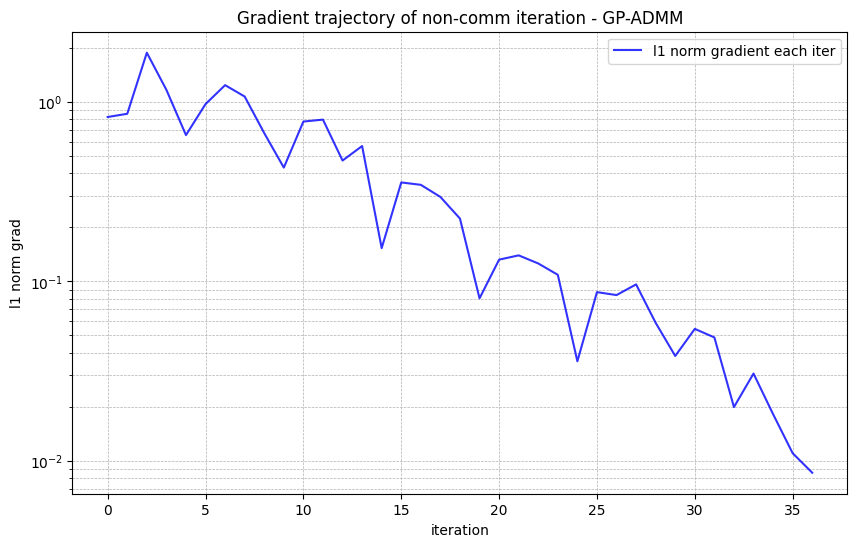

In [85]:
# sogp
sogp_err_per_iter, sogp_num_com_iter = plot_grads_error_per_iter(sogp_data, "sogp")

## MTGP

In [86]:
tmp = mtgp_data["other_stats"].apply(lambda row: extract_row_stats(row, "do_query"))
mtgp_data["var_max_max"]  = tmp.apply(lambda x: x[0])
mtgp_data["var_max_mean"] = tmp.apply(lambda x: x[1])
mtgp_data["psi_k_mean"]   = tmp.apply(lambda x: x[2])
mtgp_data["psi_k_min"]    = tmp.apply(lambda x: x[3])
mtgp_data["query_count"]  = tmp.apply(lambda x: x[4])
mtgp_stats_query_data = tmp.apply(lambda x: x[5])

<function matplotlib.pyplot.show(close=None, block=None)>

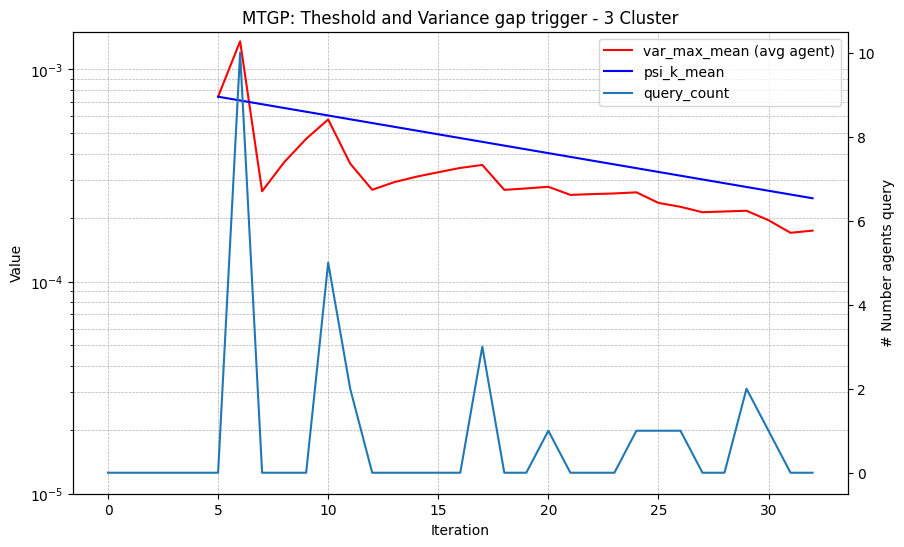

In [87]:
it = mtgp_data["iteration"].to_numpy()

fig, ax = plt.subplots(figsize=(10,6))
# ax.plot(it, mtgp_data["var_max_max"], color = "red",  label="var_max_max (worst agent)")
ax.plot(it, mtgp_data["var_max_mean"], color = "red", label="var_max_mean (avg agent)")
ax.plot(it, mtgp_data["psi_k_mean"], color = "blue",label="psi_k_mean")
ax.set_xlabel("Iteration")
ax.set_ylabel("Value")
ax.set_yscale("log")
ax.set_ylim(1e-5, None)
ax.grid(True, which="both", linestyle="--", linewidth=0.5)

ax2 = ax.twinx()
ax2.plot(it, mtgp_data["query_count"], label="query_count")
ax2.set_ylabel("# Number agents query")
ax2.set_ylim(-0.5, 10.5)

lines = ax.get_lines() + ax2.get_lines()

labels = [l.get_label() for l in lines]

ax.legend(lines, labels, loc="upper right")

plt.title("MTGP: Theshold and Variance gap trigger - 3 Cluster")

plt.show

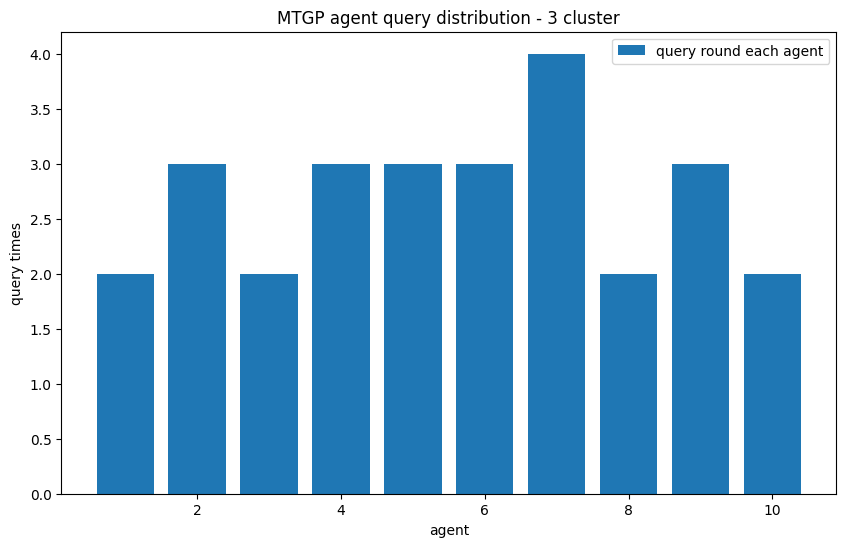

In [88]:
query_table = extract_query_stats(mtgp_stats_query_data)
query_distr = np.sum(query_table, axis=0)

plt.figure(figsize=(10,6))
plt.bar(agent, query_distr, label="query round each agent")
plt.title("MTGP agent query distribution - 3 cluster")
plt.xlabel("agent")
plt.ylabel("query times")
plt.legend()
# plt.grid(True)
plt.show()

In [89]:
# label of cluster 2
labels_clst_3

array([list([0, 0, 1, 2, 1, 2, 2, 1, 0, 0])], dtype=object)

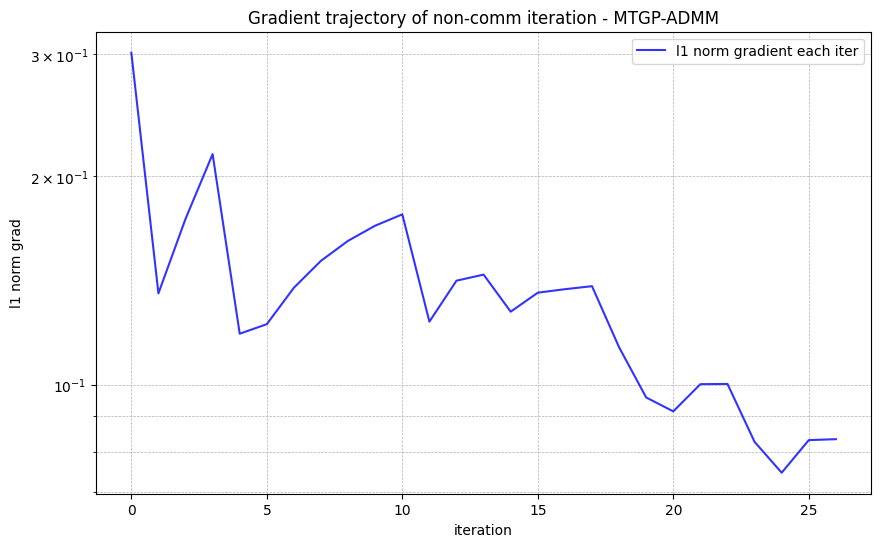

In [90]:
# gradient error
mtgp_err_per_iter, mtgp_num_com_iter = plot_grads_error_per_iter(mtgp_data, "mtgp")

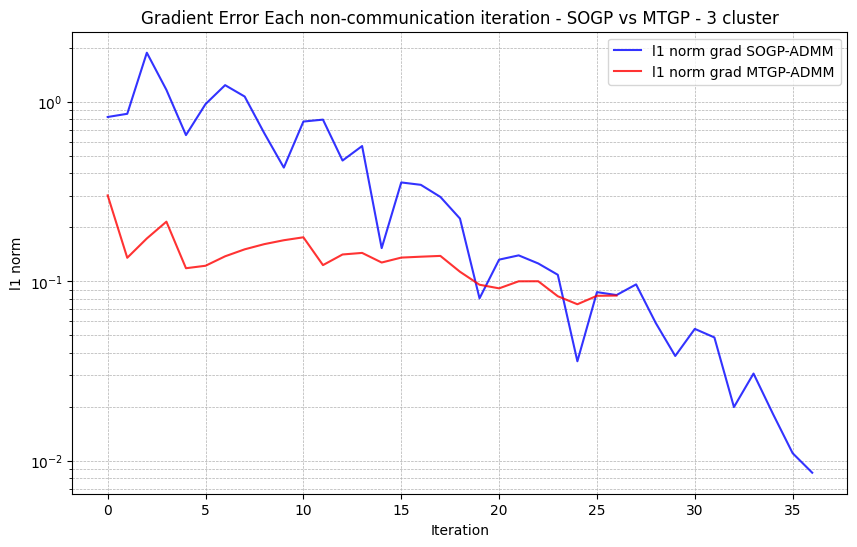

In [91]:
## ## compcare the gradient grad of the SOGP vs MTGP
plt.figure(figsize=(10,6))
plt.plot(np.linspace(0, sogp_num_com_iter-1, num=sogp_num_com_iter), sogp_err_per_iter, color="blue", alpha=0.8, label="l1 norm grad SOGP-ADMM")
plt.plot(np.linspace(0, mtgp_num_com_iter-1, num=mtgp_num_com_iter), mtgp_err_per_iter, color="red", alpha=0.8, label="l1 norm grad MTGP-ADMM")
plt.yscale("log")
plt.title("Gradient Error Each non-communication iteration - SOGP vs MTGP - 3 cluster")
plt.xlabel("Iteration")
plt.ylabel("l1 norm")
plt.legend()
plt.grid(True, which="both", linestyle="--", linewidth=0.5)
plt.show()

# Two cluster

In [20]:
# 2 clst
two_clst_admm = r"../results/cluster/c2_mtgp_admm_results_summary.jsonl"
mtgp_optim = r"../results/cluster/mtgp_sweep_alpha/set1_two_cluster/jsonl/iota_1.2_alpha_0.9600_Q_5_rank_1_train_300_lr_0.03.jsonl"
sogp_optim = r"../results/cluster/sogp_sweep_alpha/set1_two_cluster/jsonl/iota_1.1_alpha_0.8500_train_100_lr_0.01.jsonl"

## Three cluster

In [21]:
# result
three_clst_admm = r"../results/cluster/c3_vanilla_admm_results_summary.jsonl"
mtgp_optim = r"../results/cluster/mtgp_sweep_alpha/set1_three_cluster/jsonl/iota_1_alpha_0.9600_Q_5_rank_1_train_300_lr_0.03.jsonl"
sogp_optim = r"../results/cluster/sogp_sweep_alpha/set1_three_cluster/jsonl/iota_0.5_alpha_0.8000_train_100_lr_0.01.jsonl"